In [1]:
import os, json, time, math, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import monai
from monai.inferers import sliding_window_inference
from monai.losses import DiceCELoss

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| monai", monai.__version__, "| device", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GB")

<local-environment> RequestsDependencyWarning: urllib3 (2.4.0) or chardet (7.6.0)/charset_normalizer (3.4.1) doesn't match a supported version!
  warnings.warn(


torch 2.7.1 | monai 1.4.0 | device cuda
NVIDIA A100-SXM4-40GB MIG 3g.20gb 20 GB


In [2]:
# ---------------- paths (EDIT THESE) ----------------
DATA_DIR = Path("/path/to/Task03_Liver")            # contains imagesTr/ and labelsTr/
WORK_DIR = Path(os.environ.get("SCRATCH", ".")) / "liver_lesion_sampling"
PREP_DIR = WORK_DIR / "preprocessed"
RUNS_DIR = WORK_DIR / "runs"

# ---------------- preprocessing ----------------
SPACING = (1.0, 1.0, 1.5)        # mm, after RAS reorientation. Coarser = faster but hurts small lesions.
HU_MIN, HU_MAX = -200.0, 250.0   # CT window, rescaled to [0, 1]
N_PREP_WORKERS = 4

# ---------------- lesion definitions (FIX AFTER THE CENSUS, BEFORE TRAINING) ----------------
MIN_LESION_MM3 = 20.0            # components below this are ignored in sampling and evaluation
                                 # (changing it requires deleting PREP_DIR and re-running preprocessing)
SMALL_DIAM_MM = 10.0             # "small" = equivalent spherical diameter below this
MATCH_MIN_COVER = 0.10           # a lesion counts as detected if >= this fraction of its voxels is predicted tumour
FROC_THRESHOLDS = (0.1, 0.3, 0.5, 0.7, 0.9)   # 0.5 is the primary operating point

# ---------------- cross-validation ----------------
N_FOLDS = 5
SEED = 2026

# ---------------- model / training ----------------
PATCH = (96, 96, 96)
CHANNELS = (32, 64, 128, 256, 320)
ATTN_LEVELS = (0, 1)             # gates on the two highest-resolution skips, as in Tureckova et al.
BATCH_SIZE = 4
LR, WEIGHT_DECAY = 3e-4, 1e-5
AMP = True
NUM_WORKERS = 6                  # <= number of CPU cores of your Jupyter session
CKPT_EVERY = 500                 # iterations
LOG_EVERY = 50
SW_BATCH = 4
TUMOR_CROP_FRAC = 1 / 3          # identical for "lesion" and "tumor_voxel" samplers
RANDOM_CROP_FRAC = 1 / 3         # identical for all samplers; the remainder is liver/tumour foreground

# (architecture, sampler). First four = 2x2 factorial, last = control arm.
CONFIGS = [("unet", "standard"), ("unet", "lesion"),
           ("attn", "standard"), ("attn", "lesion"),
           ("unet", "tumor_voxel")]

# ---------------- pilot vs. main ----------------
PILOT = True
if PILOT:
    EXP, TOTAL_ITERS, FOLDS_TO_RUN = "pilot", 4000, [0]
else:
    EXP, TOTAL_ITERS, FOLDS_TO_RUN = "main", 25000, list(range(N_FOLDS))
MAX_HOURS_PER_CALL = None        # e.g. 7.5 to stop cleanly before an 8 h session ends

for d in (PREP_DIR, RUNS_DIR / EXP):
    d.mkdir(parents=True, exist_ok=True)
VOX_MM3 = float(np.prod(SPACING))
S26 = np.ones((3, 3, 3), dtype=bool)   # 26-connectivity for all connected-component labelling
print("experiment:", EXP, "| iterations per run:", TOTAL_ITERS, "| folds:", FOLDS_TO_RUN)

experiment: pilot | iterations per run: 4000 | folds: [0]


In [3]:
import tarfile

TAR_PATH = Path.home() / "scratch" / "Task03_Liver.tar"
EXTRACT_TO = Path.home() / "scratch" / "msd"

assert TAR_PATH.exists(), f"not found: {TAR_PATH}"
DATA_DIR = EXTRACT_TO / "Task03_Liver"
if not (DATA_DIR / "labelsTr").exists():
    EXTRACT_TO.mkdir(parents=True, exist_ok=True)
    with tarfile.open(TAR_PATH) as tar:
        tar.extractall(EXTRACT_TO)
print("DATA_DIR =", DATA_DIR)
print("labels:", len([p for p in (DATA_DIR / "labelsTr").glob("*.nii.gz") if not p.name.startswith(".")]))

DATA_DIR = <local-environment>
labels: 131


In [ ]:
case_ids = sorted(p.name[:-7] for p in (DATA_DIR / "labelsTr").glob("*.nii.gz") if not p.name.startswith("."))
assert len(case_ids) > 0, f"no labels found under {DATA_DIR / 'labelsTr'}"
for c in case_ids:
    assert (DATA_DIR / "imagesTr" / f"{c}.nii.gz").exists(), f"missing image for {c}"

folds_file = WORK_DIR / "folds.json"
if folds_file.exists():
    FOLDS = json.loads(folds_file.read_text())
else:
    perm = np.random.default_rng(SEED).permutation(len(case_ids))
    FOLDS = {str(k): sorted(case_ids[i] for i in part) for k, part in enumerate(np.array_split(perm, N_FOLDS))}
    folds_file.write_text(json.dumps(FOLDS, indent=1))
print(len(case_ids), "cases |", {k: len(v) for k, v in FOLDS.items()})

In [ ]:
def preprocess_case(cid):
    out = PREP_DIR / cid
    if (out / "info.json").exists():
        return cid
    import numpy as np, json, shutil
    from scipy import ndimage as ndi
    from monai.transforms import (Compose, LoadImaged, Orientationd, Spacingd,
                                  ScaleIntensityRanged, CropForegroundd)
    keys = ["image", "label"]
    tf = Compose([
        LoadImaged(keys=keys, ensure_channel_first=True),
        Orientationd(keys=keys, axcodes="RAS"),
        Spacingd(keys=keys, pixdim=SPACING, mode=("bilinear", "nearest")),
        ScaleIntensityRanged(keys="image", a_min=HU_MIN, a_max=HU_MAX, b_min=0.0, b_max=1.0, clip=True),
        CropForegroundd(keys=keys, source_key="image"),      # body bounding box (does not use the labels)
    ])
    d = tf({"image": str(DATA_DIR / "imagesTr" / f"{cid}.nii.gz"),
            "label": str(DATA_DIR / "labelsTr" / f"{cid}.nii.gz")})
    img = d["image"][0].cpu().numpy().astype(np.float16)
    lab = np.rint(d["label"][0].cpu().numpy()).astype(np.uint8)

    # tumour connected components (26-connectivity) at the resampled resolution
    cc, n = ndi.label(lab == 2, structure=np.ones((3, 3, 3), dtype=bool))
    sizes = np.bincount(cc.ravel(), minlength=n + 1)
    vox_mm3 = float(np.prod(SPACING))
    remap = np.zeros(n + 1, dtype=np.int16)
    lesions, new = [], 0
    for i in range(1, n + 1):
        vol = float(sizes[i]) * vox_mm3
        if vol >= MIN_LESION_MM3:
            new += 1
            remap[i] = new
            lesions.append({"id": new, "voxels": int(sizes[i]), "volume_mm3": vol,
                            "diam_mm": float((6.0 * vol / np.pi) ** (1.0 / 3.0))})
        else:
            remap[i] = -1
    lesion_map = remap[cc]

    # crop-centre candidates: tumour voxels grouped by lesion, and a subsample of liver+tumour voxels
    sel = lesion_map > 0
    tumor_coords = np.argwhere(sel).astype(np.int16)
    ids = lesion_map[sel].astype(np.int64)
    order = np.argsort(ids, kind="stable")
    tumor_coords = tumor_coords[order]
    counts = np.bincount(ids, minlength=new + 1)[1:]
    offsets = np.concatenate([[0], np.cumsum(counts)]).astype(np.int64)
    fg = np.argwhere(lab > 0)
    if len(fg) > 200_000:
        fg = fg[np.random.default_rng(0).choice(len(fg), 200_000, replace=False)]
    fg = fg.astype(np.int16)

    tmp = PREP_DIR / (cid + ".tmp")
    shutil.rmtree(tmp, ignore_errors=True)
    tmp.mkdir(parents=True)
    np.save(tmp / "image.npy", img)
    np.save(tmp / "label.npy", lab)
    np.save(tmp / "lesions.npy", lesion_map)
    np.savez(tmp / "coords.npz", tumor=tumor_coords, offsets=offsets, fg=fg,
             diams=np.array([l["diam_mm"] for l in lesions], dtype=np.float32))
    (tmp / "info.json").write_text(json.dumps({
        "case": cid, "shape": list(img.shape), "spacing": list(SPACING),
        "min_lesion_mm3": MIN_LESION_MM3, "n_ignored_components": int((remap == -1).sum()),
        "liver_voxels": int((lab > 0).sum()), "lesions": lesions}))
    shutil.rmtree(out, ignore_errors=True)
    tmp.rename(out)
    return cid

In [ ]:
from joblib import Parallel, delayed

todo = [c for c in case_ids if not (PREP_DIR / c / "info.json").exists()]
print(f"{len(case_ids) - len(todo)} cases already preprocessed, {len(todo)} to do")
if todo:
    if N_PREP_WORKERS > 1:
        Parallel(n_jobs=N_PREP_WORKERS, verbose=5)(delayed(preprocess_case)(c) for c in todo)
    else:
        for c in tqdm(todo):
            preprocess_case(c)

INFO = {c: json.loads((PREP_DIR / c / "info.json").read_text()) for c in case_ids}
bad = [c for c in case_ids if tuple(INFO[c]["spacing"]) != tuple(SPACING) or INFO[c]["min_lesion_mm3"] != MIN_LESION_MM3]
assert not bad, f"{len(bad)} cases were preprocessed with a different SPACING / MIN_LESION_MM3; delete PREP_DIR and re-run"

In [ ]:
# Optional: copy the preprocessed data to node-local disk for faster reads (repeat in each new session).
USE_LOCAL_COPY = False
if USE_LOCAL_COPY and os.environ.get("SLURM_TMPDIR"):
    local = Path(os.environ["SLURM_TMPDIR"]) / "preprocessed"
    if not local.exists():
        shutil.copytree(PREP_DIR, local)
    PREP_DIR = local
print("reading preprocessed data from", PREP_DIR)

In [ ]:
fold_of = {c: int(k) for k, v in FOLDS.items() for c in v}
census = pd.DataFrame([{"case": c, "fold": fold_of[c], **l} for c in case_ids for l in INFO[c]["lesions"]])
per_case = census.groupby("case").size().reindex(case_ids, fill_value=0)

print(f"cases: {len(case_ids)} | without any kept lesion: {(per_case == 0).sum()}")
print(f"kept lesions: {len(census)} | ignored tiny components: {sum(INFO[c]['n_ignored_components'] for c in case_ids)}")
print(f"lesions per case: median {per_case.median():.0f}, max {per_case.max()}")
census["small"] = census["diam_mm"] < SMALL_DIAM_MM
print(f"\nsmall lesions (< {SMALL_DIAM_MM} mm): {census['small'].sum()} in {census.loc[census['small'], 'case'].nunique()} patients")
print("small lesions per fold:\n", census.groupby("fold")["small"].sum().to_string())
top = census[census["small"]].groupby("case").size().sort_values(ascending=False)
if len(top):
    print(f"\nshare of small lesions held by the 5 patients with most: {top.head(5).sum() / top.sum():.0%}")
print("\ncount by diameter bin (mm):")
print(pd.cut(census["diam_mm"], [0, 5, 10, 20, 50, np.inf]).value_counts().sort_index().to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(census["diam_mm"], bins=np.logspace(0, 2.5, 40)); ax[0].set_xscale("log")
ax[0].axvline(SMALL_DIAM_MM, color="k", ls="--"); ax[0].set_xlabel("equivalent diameter (mm)"); ax[0].set_ylabel("lesions")
ax[1].hist(per_case, bins=30); ax[1].set_xlabel("kept lesions per patient"); ax[1].set_ylabel("patients")
plt.tight_layout(); plt.show()

In [ ]:
from monai.transforms import (Compose, RandFlipd, RandAffined, RandGaussianNoised,
                              RandScaleIntensityd, RandShiftIntensityd)

def make_augment():
    keys = ["image", "label"]
    return Compose([
        RandFlipd(keys=keys, prob=0.5, spatial_axis=0),
        RandFlipd(keys=keys, prob=0.5, spatial_axis=1),
        RandFlipd(keys=keys, prob=0.5, spatial_axis=2),
        RandAffined(keys=keys, prob=0.3, rotate_range=(0.26, 0.26, 0.26), scale_range=(0.15, 0.15, 0.15),
                    mode=("bilinear", "nearest"), padding_mode="zeros"),
        RandGaussianNoised(keys="image", prob=0.15, std=0.03),
        RandScaleIntensityd(keys="image", factors=0.15, prob=0.2),
        RandShiftIntensityd(keys="image", offsets=0.05, prob=0.2),
    ])

def _plain(x):
    return x.as_tensor() if hasattr(x, "as_tensor") else torch.as_tensor(x)

KIND_RANDOM, KIND_FG, KIND_TUMOR = 0, 1, 2

class PatchDataset(torch.utils.data.Dataset):
    """Each item is one random crop from a random training case."""

    def __init__(self, case_ids, sampler, length, augment=True):
        assert sampler in ("standard", "tumor_voxel", "lesion")
        self.case_ids, self.sampler, self.length = list(case_ids), sampler, int(length)
        self.aug = make_augment() if augment else None
        self._cache, self._r = {}, None

    def __len__(self):
        return self.length

    def _rng(self):
        if self._r is None:   # created inside each worker, seeded from that worker's torch seed
            self._r = np.random.default_rng(int(torch.randint(0, 2**31 - 1, (1,)).item()))
        return self._r

    def _case(self, cid):
        if cid not in self._cache:
            z = np.load(PREP_DIR / cid / "coords.npz")
            self._cache[cid] = {
                "image": np.load(PREP_DIR / cid / "image.npy", mmap_mode="r"),
                "label": np.load(PREP_DIR / cid / "label.npy", mmap_mode="r"),
                "tumor": z["tumor"], "offsets": z["offsets"], "fg": z["fg"], "diams": z["diams"]}
        return self._cache[cid]

    def _center(self, c, rng):
        shape = c["image"].shape
        n_les = len(c["diams"])
        u = rng.random()
        want_tumor = self.sampler != "standard" and u >= 1.0 - TUMOR_CROP_FRAC
        if u < RANDOM_CROP_FRAC or len(c["fg"]) == 0:
            return np.array([rng.integers(s) for s in shape]), KIND_RANDOM, -1.0
        if want_tumor and n_les > 0:
            if self.sampler == "tumor_voxel":
                row = int(rng.integers(len(c["tumor"])))
                li = int(np.searchsorted(c["offsets"], row, side="right") - 1)
            else:
                li = int(rng.integers(n_les))
                row = int(rng.integers(c["offsets"][li], c["offsets"][li + 1]))
            return c["tumor"][row].astype(np.int64), KIND_TUMOR, float(c["diams"][li])
        return c["fg"][rng.integers(len(c["fg"]))].astype(np.int64), KIND_FG, -1.0

    def __getitem__(self, idx):
        rng = self._rng()
        c = self._case(self.case_ids[int(rng.integers(len(self.case_ids)))])
        center, kind, diam = self._center(c, rng)
        shape = c["image"].shape
        sl = []
        for a in range(3):
            p = PATCH[a]
            jitter = int(rng.integers(-(p // 4), p // 4 + 1))      # target is not always dead centre
            start = int(np.clip(center[a] + jitter - p // 2, 0, max(shape[a] - p, 0)))
            sl.append(slice(start, min(start + p, shape[a])))
        img = np.array(c["image"][tuple(sl)], dtype=np.float32)
        lab = np.array(c["label"][tuple(sl)], dtype=np.uint8)
        if img.shape != tuple(PATCH):
            pad = [(0, PATCH[a] - img.shape[a]) for a in range(3)]
            img, lab = np.pad(img, pad), np.pad(lab, pad)
        d = {"image": img[None], "label": lab[None]}
        if self.aug is not None:
            d = self.aug(d)
        return {"image": _plain(d["image"]).float().contiguous(),
                "label": _plain(d["label"]).long().contiguous(),
                "kind": kind, "diam": diam}

In [ ]:
class ConvBlock(nn.Sequential):
    def __init__(self, cin, cout, stride=1):
        super().__init__(
            nn.Conv3d(cin, cout, 3, stride, 1, bias=False), nn.InstanceNorm3d(cout, affine=True), nn.LeakyReLU(0.01, inplace=True),
            nn.Conv3d(cout, cout, 3, 1, 1, bias=False), nn.InstanceNorm3d(cout, affine=True), nn.LeakyReLU(0.01, inplace=True))

class AttentionGate(nn.Module):
    def __init__(self, c_x, c_g, c_int):
        super().__init__()
        self.wx = nn.Conv3d(c_x, c_int, 1, bias=False)
        self.wg = nn.Conv3d(c_g, c_int, 1)
        self.psi = nn.Conv3d(c_int, 1, 1)
        nn.init.constant_(self.psi.bias, 3.0)      # sigmoid(3) ~ 0.95: gate starts open
        self.keep_map, self.last_map = False, None

    def forward(self, x, g):
        alpha = torch.sigmoid(self.psi(F.relu(self.wx(x) + self.wg(g))))
        if self.keep_map:
            self.last_map = alpha.detach().float().cpu()
        return x * alpha

class UNet3D(nn.Module):
    def __init__(self, in_ch=1, n_classes=3, channels=CHANNELS, attention=False, attn_levels=ATTN_LEVELS):
        super().__init__()
        ch = list(channels)
        self.enc = nn.ModuleList([ConvBlock(in_ch, ch[0])] + [ConvBlock(ch[i - 1], ch[i], 2) for i in range(1, len(ch))])
        self.up, self.dec, self.gates = nn.ModuleList(), nn.ModuleList(), nn.ModuleDict()
        self.levels = list(reversed(range(len(ch) - 1)))
        for i in self.levels:
            self.up.append(nn.ConvTranspose3d(ch[i + 1], ch[i], 2, 2))
            self.dec.append(ConvBlock(2 * ch[i], ch[i]))
            if attention and i in attn_levels:
                self.gates[str(i)] = AttentionGate(ch[i], ch[i], max(ch[i] // 2, 8))
        self.head = nn.Conv3d(ch[0], n_classes, 1)

    def forward(self, x):
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x)
            if i < len(self.enc) - 1:
                skips.append(x)
        for k, i in enumerate(self.levels):
            x = self.up[k](x)
            s = skips[i]
            if str(i) in self.gates:
                s = self.gates[str(i)](s, x)
            x = self.dec[k](torch.cat([s, x], dim=1))
        return self.head(x)

def build_model(arch):
    assert arch in ("unet", "attn")
    return UNet3D(attention=(arch == "attn"))

for a in ("unet", "attn"):
    print(a, f"{sum(p.numel() for p in build_model(a).parameters()) / 1e6:.3f} M parameters")

In [ ]:
rows = []
for s in ("standard", "tumor_voxel", "lesion"):
    ds = PatchDataset(FOLDS["1"] + FOLDS["2"], s, 400, augment=False)
    kinds, diams, tumor_frac = [], [], []
    for i in range(len(ds)):
        b = ds[i]
        kinds.append(b["kind"]); diams.append(b["diam"]); tumor_frac.append(float((b["label"] == 2).any()))
    kinds, diams = np.array(kinds), np.array(diams)
    t = kinds == KIND_TUMOR
    rows.append({"sampler": s, "random": (kinds == KIND_RANDOM).mean(), "foreground": (kinds == KIND_FG).mean(),
                 "tumour-centred": t.mean(), "crops containing tumour": np.mean(tumor_frac),
                 "median target diam (mm)": np.median(diams[t]) if t.any() else np.nan,
                 "small targets / tumour crops": (diams[t] < SMALL_DIAM_MM).mean() if t.any() else np.nan})
display(pd.DataFrame(rows).set_index("sampler").round(3))

In [ ]:
ds = PatchDataset(FOLDS["1"], "lesion", 6, augment=True)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j in range(6):
    b = ds[j]
    z = PATCH[2] // 2
    axes[0, j].imshow(b["image"][0, :, :, z].T, cmap="gray", origin="lower", vmin=0, vmax=1)
    axes[1, j].imshow(b["label"][0, :, :, z].T, origin="lower", vmin=0, vmax=2)
    axes[0, j].set_title(["random", "foreground", f"tumour {b['diam']:.0f} mm"][b["kind"]]); axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
if DEVICE.type == "cuda":
    m = build_model("attn").to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    x = torch.rand(BATCH_SIZE, 1, *PATCH, device=DEVICE); y = torch.randint(0, 3, (BATCH_SIZE, 1, *PATCH), device=DEVICE)
    lf = DiceCELoss(to_onehot_y=True, softmax=True)
    torch.cuda.reset_peak_memory_stats(); t0 = time.time()
    for _ in range(5):
        with torch.autocast("cuda", enabled=AMP):
            out = m(x)
        loss = lf(out.float(), y); opt.zero_grad(); loss.backward(); opt.step()
    torch.cuda.synchronize()
    its = 5 / (time.time() - t0)
    print(f"peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.1f} GB | ~{its:.1f} it/s (GPU only) "
          f"| {TOTAL_ITERS} iterations ~ {TOTAL_ITERS / its / 3600:.1f} h per run before data-loading overhead")
    del m, opt, x, y, out, loss; torch.cuda.empty_cache()

In [ ]:
def run_dir(arch, sampler, fold):
    return RUNS_DIR / EXP / f"{arch}__{sampler}__fold{fold}"

def _atomic_save(obj, path):
    tmp = Path(str(path) + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

def _grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=AMP and DEVICE.type == "cuda")
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=AMP and DEVICE.type == "cuda")

def train_run(arch, sampler, fold, deadline=None):
    """Returns True when the run is complete, False if it stopped early at the deadline."""
    rd = run_dir(arch, sampler, fold)
    rd.mkdir(parents=True, exist_ok=True)
    if (rd / "final.pt").exists():
        return True

    model = build_model(arch).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda it: max(0.0, 1.0 - it / TOTAL_ITERS) ** 0.9)
    scaler = _grad_scaler()
    loss_fn = DiceCELoss(to_onehot_y=True, softmax=True)
    it0 = 0
    if (rd / "last.pt").exists():
        ck = torch.load(rd / "last.pt", map_location=DEVICE, weights_only=False)
        assert ck["total_iters"] == TOTAL_ITERS, "checkpoint was made with a different TOTAL_ITERS"
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        it0 = ck["iter"]
    torch.manual_seed(SEED + 1000 * fold + it0)

    train_ids = [c for k, v in FOLDS.items() if int(k) != fold for c in v]
    ds = PatchDataset(train_ids, sampler, (TOTAL_ITERS - it0) * BATCH_SIZE)
    dl = monai.data.DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                               pin_memory=True, drop_last=True)
    log_path = rd / "train_log.csv"
    if it0 == 0:
        log_path.write_text("iter,loss,lr,frac_tumor_crops,frac_small_target,it_per_s\n")

    def checkpoint(it):
        _atomic_save({"iter": it, "total_iters": TOTAL_ITERS, "model": model.state_dict(), "opt": opt.state_dict(),
                      "sched": sched.state_dict(), "scaler": scaler.state_dict()}, rd / "last.pt")

    model.train()
    acc_loss, n_crops, n_tumor, n_small, t_log = 0.0, 0, 0, 0, time.time()
    pbar = tqdm(dl, initial=it0, total=TOTAL_ITERS, desc=f"{arch}/{sampler}/fold{fold}", leave=False)
    it = it0
    for it, batch in enumerate(pbar, start=it0 + 1):
        x = batch["image"].to(DEVICE, non_blocking=True)
        y = batch["label"].to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE.type, enabled=AMP and DEVICE.type == "cuda"):
            logits = model(x)
        loss = loss_fn(logits.float(), y)
        if not torch.isfinite(loss):
            raise RuntimeError(f"non-finite loss at iteration {it} in {rd.name}")
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 12.0)
        scaler.step(opt); scaler.update(); sched.step()

        acc_loss += loss.item(); n_crops += len(batch["kind"])
        is_t = batch["kind"] == KIND_TUMOR
        n_tumor += int(is_t.sum()); n_small += int((is_t & (batch["diam"] < SMALL_DIAM_MM)).sum())
        if it % LOG_EVERY == 0:
            ips = LOG_EVERY / (time.time() - t_log)
            with open(log_path, "a") as f:
                f.write(f"{it},{acc_loss / LOG_EVERY:.5f},{sched.get_last_lr()[0]:.3e},"
                        f"{n_tumor / n_crops:.4f},{n_small / n_crops:.4f},{ips:.2f}\n")
            pbar.set_postfix(loss=f"{acc_loss / LOG_EVERY:.3f}", it_s=f"{ips:.1f}")
            acc_loss, n_crops, n_tumor, n_small, t_log = 0.0, 0, 0, 0, time.time()
        if it % CKPT_EVERY == 0 and it < TOTAL_ITERS:
            checkpoint(it)
            if deadline is not None and time.time() > deadline:
                print(f"time budget reached: {rd.name} paused at iteration {it}")
                return False

    assert it == TOTAL_ITERS, f"stopped at {it}, expected {TOTAL_ITERS}"
    _atomic_save({"model": model.state_dict(), "arch": arch, "sampler": sampler, "fold": fold,
                  "total_iters": TOTAL_ITERS}, rd / "final.pt")
    (rd / "last.pt").unlink(missing_ok=True)
    return True

In [ ]:
def score_case(cid, p_bg, p_tumor):
    """Whole-volume metrics for one case. Pure numpy; all thresholds come from the config cell."""
    lab = np.load(PREP_DIR / cid / "label.npy")
    lm = np.load(PREP_DIR / cid / "lesions.npy").astype(np.int64)
    diams = np.array([l["diam_mm"] for l in INFO[cid]["lesions"]], dtype=float)
    K = len(diams)
    small = diams < SMALL_DIAM_MM
    tumor_gt = lab == 2                       # includes ignored tiny components, so they never count as false positives
    kept = lm > 0
    tot = np.bincount(lm[kept], minlength=K + 1)[1:]

    liver_gt, liver_pred = lab > 0, p_bg < 0.5
    denom = liver_gt.sum() + liver_pred.sum()
    case = {"case": cid, "liver_dice": 2.0 * (liver_gt & liver_pred).sum() / denom if denom else np.nan,
            "n_lesions": K, "n_small": int(small.sum())}
    lesion_rows, froc_rows = [], []
    for t in FROC_THRESHOLDS:
        pcc, n = ndi.label(p_tumor > t, structure=S26)
        psize = np.bincount(pcc.ravel(), minlength=n + 1)
        keep = psize * VOX_MM3 >= MIN_LESION_MM3      # predicted components below the minimum size are dropped
        keep[0] = False
        pred = keep[pcc]
        hit = np.zeros(n + 1, dtype=bool)
        hit[np.unique(pcc[tumor_gt])] = True
        n_fp = int((keep & ~hit).sum())               # predicted components touching no ground-truth tumour voxel
        cover = np.bincount(lm[kept & pred], minlength=K + 1)[1:] / np.maximum(tot, 1)
        det = cover >= MATCH_MIN_COVER
        froc_rows.append({"case": cid, "threshold": t, "n_fp": n_fp, "n_all": K, "n_all_det": int(det.sum()),
                          "n_small": int(small.sum()), "n_small_det": int((det & small).sum())})
        if abs(t - 0.5) < 1e-9:
            d2 = tumor_gt.sum() + pred.sum()
            case.update({"tumor_dice": 2.0 * (tumor_gt & pred).sum() / d2 if tumor_gt.any() else np.nan,  # only defined when GT tumour exists
                         "n_fp": n_fp, "n_det": int(det.sum()), "n_small_det": int((det & small).sum())})
            lesion_rows = [{"case": cid, "lesion": i + 1, "diam_mm": diams[i], "small": bool(small[i]),
                            "cover": float(cover[i]), "detected": bool(det[i])} for i in range(K)]
    return case, lesion_rows, froc_rows

@torch.no_grad()
def evaluate_run(arch, sampler, fold, force=False):
    rd = run_dir(arch, sampler, fold)
    if (rd / "froc.csv").exists() and not force:
        return
    model = build_model(arch).to(DEVICE)
    model.load_state_dict(torch.load(rd / "final.pt", map_location=DEVICE, weights_only=False)["model"])
    model.eval()
    cases, lesions, froc = [], [], []
    for cid in tqdm(FOLDS[str(fold)], desc=f"eval {rd.name}", leave=False):
        x = torch.from_numpy(np.load(PREP_DIR / cid / "image.npy").astype(np.float32))[None, None]
        with torch.autocast(DEVICE.type, enabled=AMP and DEVICE.type == "cuda"):
            logits = sliding_window_inference(x, PATCH, SW_BATCH, model, overlap=0.5, mode="gaussian",
                                              sw_device=DEVICE, device="cpu")
        prob = torch.softmax(logits[0].float(), dim=0).numpy()
        c, l, f = score_case(cid, prob[0], prob[2])
        cases.append(c); lesions += l; froc += f
        del logits, prob
    tag = {"arch": arch, "sampler": sampler, "fold": fold}
    pd.DataFrame(cases).assign(**tag).to_csv(rd / "cases.csv", index=False)
    pd.DataFrame(lesions, columns=["case", "lesion", "diam_mm", "small", "cover", "detected"]).assign(**tag).to_csv(rd / "lesions.csv", index=False)
    pd.DataFrame(froc).assign(**tag).to_csv(rd / "froc.csv", index=False)   # written last: marks the run as evaluated

def status():
    rows = []
    for fold in FOLDS_TO_RUN:
        for arch, sampler in CONFIGS:
            rd = run_dir(arch, sampler, fold)
            it = TOTAL_ITERS if (rd / "final.pt").exists() else 0
            if not it and (rd / "train_log.csv").exists():
                log = pd.read_csv(rd / "train_log.csv")
                it = int(log["iter"].iloc[-1]) if len(log) else 0
            rows.append({"fold": fold, "config": f"{arch}/{sampler}", "iter": it,
                         "trained": (rd / "final.pt").exists(), "evaluated": (rd / "froc.csv").exists()})
    return pd.DataFrame(rows)

In [ ]:
deadline = time.time() + MAX_HOURS_PER_CALL * 3600 if MAX_HOURS_PER_CALL else None
stopped = False
for fold in FOLDS_TO_RUN:
    for arch, sampler in CONFIGS:
        if not train_run(arch, sampler, fold, deadline):
            stopped = True
            break
        evaluate_run(arch, sampler, fold)
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    if stopped:
        break
display(status())

In [ ]:
# Training curves and realised crop mix for the runs of one fold
fold = FOLDS_TO_RUN[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for arch, sampler in CONFIGS:
    p = run_dir(arch, sampler, fold) / "train_log.csv"
    if p.exists() and len(log := pd.read_csv(p)):
        ax[0].plot(log["iter"], log["loss"].rolling(10, min_periods=1).mean(), label=f"{arch}/{sampler}")
        ax[1].plot(log["iter"], log["frac_small_target"].rolling(10, min_periods=1).mean(), label=f"{arch}/{sampler}")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("training loss"); ax[0].legend()
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("fraction of crops centred on a small lesion")
plt.tight_layout(); plt.show()

In [ ]:
def load_results(name):
    frames = []
    for fold in FOLDS_TO_RUN:
        for arch, sampler in CONFIGS:
            p = run_dir(arch, sampler, fold) / name
            if (run_dir(arch, sampler, fold) / "froc.csv").exists():
                frames.append(pd.read_csv(p))
    if not frames:
        return pd.DataFrame()
    df = pd.concat(frames, ignore_index=True)
    df["config"] = df["arch"] + "/" + df["sampler"]
    return df

cases_df, lesions_df, froc_df = load_results("cases.csv"), load_results("lesions.csv"), load_results("froc.csv")
assert len(cases_df), "no evaluated runs yet"

g = cases_df.groupby("config")
summary = pd.DataFrame({
    "patients": g.size(),
    "small-lesion sensitivity": g["n_small_det"].sum() / g["n_small"].sum(),
    "all-lesion sensitivity": g["n_det"].sum() / g["n_lesions"].sum(),
    "FP per scan": g["n_fp"].mean(),
    "tumour Dice (cases with tumour)": g["tumor_dice"].mean(),
    "liver Dice": g["liver_dice"].mean()})
display(summary.round(3))

if len(lesions_df):
    lesions_df["size bin (mm)"] = pd.cut(lesions_df["diam_mm"], [0, 10, 20, np.inf])
    print("lesion-wise sensitivity by size (n lesions in brackets is the same for every configuration)")
    display(lesions_df.groupby(["config", "size bin (mm)"], observed=True)["detected"].mean().unstack().round(3))
    display(lesions_df.groupby("size bin (mm)", observed=True)["lesion"].size().div(lesions_df["config"].nunique()).rename("n lesions").to_frame().T)

In [ ]:
def _metric(tab, idx, metric):
    """tab: dict of per-patient arrays; idx: (n_boot, n_patients) resampling indices."""
    if metric == "small_sens":
        return tab["n_small_det"][idx].sum(1) / np.maximum(tab["n_small"][idx].sum(1), 1)
    if metric == "fp_per_scan":
        return tab["n_fp"][idx].mean(1)
    if metric == "tumor_dice":
        return np.nanmean(tab["tumor_dice"][idx], axis=1)
    raise ValueError(metric)

def paired_bootstrap(weights, metric, n_boot=5000, seed=0):
    """weights: {config: weight}. Returns the point estimate and 95% CI of sum_k w_k * metric(config k)."""
    if any(c not in set(cases_df["config"]) for c in weights):
        return None
    wide = {c: cases_df[cases_df["config"] == c].set_index("case") for c in weights}
    common = sorted(set.intersection(*(set(w.index) for w in wide.values())))
    tabs = {c: {k: w.loc[common, k].to_numpy(dtype=float) for k in ("n_small", "n_small_det", "n_fp", "tumor_dice")}
            for c, w in wide.items()}
    n = len(common)
    idx = np.random.default_rng(seed).integers(0, n, size=(n_boot, n))
    point = sum(w * _metric(tabs[c], np.arange(n)[None], metric)[0] for c, w in weights.items())
    boot = sum(w * _metric(tabs[c], idx, metric) for c, w in weights.items())
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    return {"estimate": point, "ci_low": lo, "ci_high": hi, "patients": n}

CONTRASTS = {
    "H1/H2  lesion - standard (U-Net)":               {"unet/lesion": 1, "unet/standard": -1},
    "H1/H2  lesion - standard (attention)":           {"attn/lesion": 1, "attn/standard": -1},
    "control  lesion - tumour-voxel (U-Net)":         {"unet/lesion": 1, "unet/tumor_voxel": -1},
    "control  tumour-voxel - standard (U-Net)":       {"unet/tumor_voxel": 1, "unet/standard": -1},
    "attention - U-Net (standard sampling)":          {"attn/standard": 1, "unet/standard": -1},
    "attention - U-Net (lesion sampling)":            {"attn/lesion": 1, "unet/lesion": -1},
    "H3  interaction (exploratory)":                  {"attn/lesion": 1, "attn/standard": -1, "unet/lesion": -1, "unet/standard": 1},
}
rows = []
for name, w in CONTRASTS.items():
    for metric in ("small_sens", "fp_per_scan", "tumor_dice"):
        r = paired_bootstrap(w, metric)
        if r:
            rows.append({"contrast": name, "metric": metric, **r})
if rows:
    display(pd.DataFrame(rows).set_index(["contrast", "metric"]).round(3))
else:
    print("not enough evaluated configurations for any contrast yet")

In [ ]:
# FROC: small-lesion sensitivity against false positives per scan, and sensitivity at a matched false-positive rate
fg = froc_df.groupby(["config", "threshold"])
froc = pd.DataFrame({"fp_per_scan": fg["n_fp"].mean(),
                     "small_sens": fg["n_small_det"].sum() / fg["n_small"].sum(),
                     "all_sens": fg["n_all_det"].sum() / fg["n_all"].sum()}).reset_index()
fig, ax = plt.subplots(figsize=(6, 4))
for cfg, d in froc.groupby("config"):
    d = d.sort_values("fp_per_scan")
    ax.plot(d["fp_per_scan"], d["small_sens"], marker="o", label=cfg)
ax.set_xlabel("false positives per scan"); ax.set_ylabel(f"sensitivity, lesions < {SMALL_DIAM_MM:g} mm"); ax.legend()
plt.tight_layout(); plt.show()

REF = "unet/standard"
if REF in set(froc["config"]):
    ref_fp = float(froc[(froc["config"] == REF) & (froc["threshold"] == 0.5)]["fp_per_scan"].iloc[0])
    matched = {}
    for cfg, d in froc.groupby("config"):
        d = d.sort_values("fp_per_scan")
        inside = d["fp_per_scan"].min() <= ref_fp <= d["fp_per_scan"].max()
        matched[cfg] = float(np.interp(ref_fp, d["fp_per_scan"], d["small_sens"])) if inside else np.nan
    print(f"small-lesion sensitivity at {ref_fp:.2f} FP/scan (the rate of {REF} at threshold 0.5; NaN = outside the measured range)")
    display(pd.Series(matched, name="small_sens @ matched FP").round(3).to_frame())

In [ ]:
out = RUNS_DIR / EXP / "results"
out.mkdir(exist_ok=True)
summary.to_csv(out / "summary.csv"); froc.to_csv(out / "froc.csv", index=False)
if rows:
    pd.DataFrame(rows).to_csv(out / "contrasts.csv", index=False)
cases_df.to_csv(out / "all_cases.csv", index=False); lesions_df.to_csv(out / "all_lesions.csv", index=False)
print("saved to", out)

In [22]:
ds = PatchDataset(FOLDS["1"] + FOLDS["2"], "lesion", 300, augment=False)
hits = [bool((b["label"] == 2).any()) for b in (ds[i] for i in range(300)) if b["kind"] == KIND_TUMOR]
print(f"{np.mean(hits):.1%} of {len(hits)} tumour-centred crops contain tumour (expect 100%)")

100.0% of 99 tumour-centred crops contain tumour (expect 100%)


In [23]:
train_run("unet", "standard", 0)
evaluate_run("unet", "standard", 0)
display(pd.read_csv(run_dir("unet", "standard", 0) / "cases.csv")[["liver_dice", "tumor_dice", "n_fp"]].describe().round(3))

,liver_dice,tumor_dice,n_fp
count,27.000,23.000,27.000
mean,0.815,0.362,18.519
std,0.083,0.223,11.950
min,0.579,0.000,3.000
25%,0.783,0.182,10.000
50%,0.827,0.420,16.000
75%,0.876,0.530,23.000
max,0.912,0.801,55.000


In [ ]:
PILOT = True
EXP, TOTAL_ITERS, FOLDS_TO_RUN = "main", 25000, list(range(N_FOLDS))
(RUNS_DIR / EXP).mkdir(parents=True, exist_ok=True)
print("experiment:", EXP, "| iterations per run:", TOTAL_ITERS, "| folds:", FOLDS_TO_RUN)

In [24]:
assert EXP == "main" and TOTAL_ITERS == 25000, f"still in {EXP} mode with {TOTAL_ITERS} iterations"
train_run("unet", "standard", 0)
evaluate_run("unet", "standard", 0)
display(pd.read_csv(run_dir("unet", "standard", 0) / "cases.csv")[["liver_dice", "tumor_dice", "n_fp"]].describe().round(3))

,liver_dice,tumor_dice,n_fp
count,27.000,23.000,27.000
mean,0.926,0.619,8.741
std,0.050,0.204,9.804
min,0.749,0.122,0.000
25%,0.909,0.475,2.500
50%,0.938,0.702,7.000
75%,0.961,0.757,11.500
max,0.978,0.904,50.000


In [ ]:
log = pd.read_csv(run_dir("unet", "standard", 0) / "train_log.csv")
print(log["loss"].iloc[-200:-100].mean().round(4), "->", log["loss"].iloc[-100:].mean().round(4))
print("speed:", log["it_per_s"].median(), "it/s")

In [25]:
#2ND TRACK

In [1]:
import os, json, time, math, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import monai
from monai.inferers import sliding_window_inference
from monai.losses import DiceCELoss

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| monai", monai.__version__, "| device", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GB")

<local-environment> RequestsDependencyWarning: urllib3 (2.4.0) or chardet (7.6.0)/charset_normalizer (3.4.1) doesn't match a supported version!
  warnings.warn(


torch 2.7.1 | monai 1.4.0 | device cuda
NVIDIA A100-SXM4-40GB MIG 3g.20gb 20 GB


In [2]:
# ---------------- paths (EDIT THESE) ----------------
TAR_PATH = Path.home() / "scratch" / "Task03_Liver.tar"
DATA_DIR = Path.home() / "scratch" / "msd" / "Task03_Liver"   # contains imagesTr/ and labelsTr/ (extracted below)
WORK_DIR = Path(os.environ.get("SCRATCH", ".")) / "liver_lesion_sampling"
PREP_DIR = WORK_DIR / "preprocessed"
RUNS_DIR = WORK_DIR / "runs"

# ---------------- preprocessing ----------------
SPACING = (1.0, 1.0, 1.5)        # mm, after RAS reorientation. Coarser = faster but hurts small lesions.
HU_MIN, HU_MAX = -200.0, 250.0   # CT window, rescaled to [0, 1]
N_PREP_WORKERS = 4

# ---------------- lesion definitions (FIX AFTER THE CENSUS, BEFORE TRAINING) ----------------
MIN_LESION_MM3 = 20.0            # components below this are ignored in sampling and evaluation
                                 # (changing it requires deleting PREP_DIR and re-running preprocessing)
SMALL_DIAM_MM = 10.0             # "small" = equivalent spherical diameter below this
MATCH_MIN_COVER = 0.10           # a lesion counts as detected if >= this fraction of its voxels is predicted tumour
FROC_THRESHOLDS = (0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95)   # 0.5 is the primary operating point
LIVER_MARGIN_VOX = 3             # secondary analysis: keep tumour predictions within this many voxels of the predicted liver

# ---------------- cross-validation ----------------
N_FOLDS = 5
SEED = 2026

# ---------------- model / training ----------------
PATCH = (96, 96, 96)
CHANNELS = (32, 64, 128, 256, 320)
ATTN_LEVELS = (0, 1)             # gates on the two highest-resolution skips, as in Tureckova et al.
BATCH_SIZE = 4
LR, WEIGHT_DECAY = 3e-4, 1e-5
AMP = True
NUM_WORKERS = 6                  # <= number of CPU cores of your Jupyter session
CKPT_EVERY = 500                 # iterations
LOG_EVERY = 50
SW_BATCH = 4
# test-time mirroring: predictions are averaged over these flips. All 8 = as in the paper, but 8x inference time.
# Cheaper options: [(), (0,), (1,), (0, 1)] (4x) or [()] (off). Keep it identical for every run.
TTA_AXES = [(), (0,), (1,), (2,), (0, 1), (0, 2), (1, 2), (0, 1, 2)]
TUMOR_CROP_FRAC = 1 / 3          # identical for "lesion" and "tumor_voxel" samplers
RANDOM_CROP_FRAC = 1 / 3         # identical for all samplers; the remainder is liver/tumour foreground

# (architecture, sampler). First four = 2x2 factorial, last = control arm.
CONFIGS = [("unet", "standard"), ("unet", "lesion"),
           ("attn", "standard"), ("attn", "lesion"),
           ("unet", "tumor_voxel")]

# ---------------- pilot vs. main ----------------
PILOT = False
if PILOT:
    EXP, TOTAL_ITERS, FOLDS_TO_RUN = "pilot", 4000, [0]
else:
    EXP, TOTAL_ITERS, FOLDS_TO_RUN = "main", 25000, list(range(N_FOLDS))
MAX_HOURS_PER_CALL = None        # e.g. 7.5 to stop cleanly before an 8 h session ends

for d in (PREP_DIR, RUNS_DIR / EXP):
    d.mkdir(parents=True, exist_ok=True)
VOX_MM3 = float(np.prod(SPACING))
S26 = np.ones((3, 3, 3), dtype=bool)   # 26-connectivity for all connected-component labelling
print("experiment:", EXP, "| iterations per run:", TOTAL_ITERS, "| folds:", FOLDS_TO_RUN)

experiment: main | iterations per run: 25000 | folds: [0, 1, 2, 3, 4]


In [3]:
# Extract the dataset once (skipped when already extracted)
import tarfile
if not (DATA_DIR / "labelsTr").exists():
    assert TAR_PATH.exists(), f"not found: {TAR_PATH}"
    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    with tarfile.open(TAR_PATH) as tar:
        tar.extractall(DATA_DIR.parent)
print("DATA_DIR =", DATA_DIR)

DATA_DIR = <local-environment>


In [4]:
case_ids = sorted(p.name[:-7] for p in (DATA_DIR / "labelsTr").glob("*.nii.gz") if not p.name.startswith("."))
assert len(case_ids) > 0, f"no labels found under {DATA_DIR / 'labelsTr'}"
for c in case_ids:
    assert (DATA_DIR / "imagesTr" / f"{c}.nii.gz").exists(), f"missing image for {c}"

folds_file = WORK_DIR / "folds.json"
if folds_file.exists():
    FOLDS = json.loads(folds_file.read_text())
else:
    perm = np.random.default_rng(SEED).permutation(len(case_ids))
    FOLDS = {str(k): sorted(case_ids[i] for i in part) for k, part in enumerate(np.array_split(perm, N_FOLDS))}
    folds_file.write_text(json.dumps(FOLDS, indent=1))
print(len(case_ids), "cases |", {k: len(v) for k, v in FOLDS.items()})

131 cases | {'0': 27, '1': 26, '2': 26, '3': 26, '4': 26}


In [5]:
def preprocess_case(cid):
    out = PREP_DIR / cid
    if (out / "info.json").exists():
        return cid
    import numpy as np, json, shutil
    from scipy import ndimage as ndi
    from monai.transforms import (Compose, LoadImaged, Orientationd, Spacingd,
                                  ScaleIntensityRanged, CropForegroundd)
    keys = ["image", "label"]
    tf = Compose([
        LoadImaged(keys=keys, ensure_channel_first=True),
        Orientationd(keys=keys, axcodes="RAS"),
        Spacingd(keys=keys, pixdim=SPACING, mode=("bilinear", "nearest")),
        ScaleIntensityRanged(keys="image", a_min=HU_MIN, a_max=HU_MAX, b_min=0.0, b_max=1.0, clip=True),
        CropForegroundd(keys=keys, source_key="image"),      # body bounding box (does not use the labels)
    ])
    d = tf({"image": str(DATA_DIR / "imagesTr" / f"{cid}.nii.gz"),
            "label": str(DATA_DIR / "labelsTr" / f"{cid}.nii.gz")})
    img = d["image"][0].cpu().numpy().astype(np.float16)
    lab = np.rint(d["label"][0].cpu().numpy()).astype(np.uint8)

    # tumour connected components (26-connectivity) at the resampled resolution
    cc, n = ndi.label(lab == 2, structure=np.ones((3, 3, 3), dtype=bool))
    sizes = np.bincount(cc.ravel(), minlength=n + 1)
    vox_mm3 = float(np.prod(SPACING))
    remap = np.zeros(n + 1, dtype=np.int16)
    lesions, new = [], 0
    for i in range(1, n + 1):
        vol = float(sizes[i]) * vox_mm3
        if vol >= MIN_LESION_MM3:
            new += 1
            remap[i] = new
            lesions.append({"id": new, "voxels": int(sizes[i]), "volume_mm3": vol,
                            "diam_mm": float((6.0 * vol / np.pi) ** (1.0 / 3.0))})
        else:
            remap[i] = -1
    lesion_map = remap[cc]

    # crop-centre candidates: tumour voxels grouped by lesion, and a subsample of liver+tumour voxels
    sel = lesion_map > 0
    tumor_coords = np.argwhere(sel).astype(np.int16)
    ids = lesion_map[sel].astype(np.int64)
    order = np.argsort(ids, kind="stable")
    tumor_coords = tumor_coords[order]
    counts = np.bincount(ids, minlength=new + 1)[1:]
    offsets = np.concatenate([[0], np.cumsum(counts)]).astype(np.int64)
    fg = np.argwhere(lab > 0)
    if len(fg) > 200_000:
        fg = fg[np.random.default_rng(0).choice(len(fg), 200_000, replace=False)]
    fg = fg.astype(np.int16)

    tmp = PREP_DIR / (cid + ".tmp")
    shutil.rmtree(tmp, ignore_errors=True)
    tmp.mkdir(parents=True)
    np.save(tmp / "image.npy", img)
    np.save(tmp / "label.npy", lab)
    np.save(tmp / "lesions.npy", lesion_map)
    np.savez(tmp / "coords.npz", tumor=tumor_coords, offsets=offsets, fg=fg,
             diams=np.array([l["diam_mm"] for l in lesions], dtype=np.float32))
    (tmp / "info.json").write_text(json.dumps({
        "case": cid, "shape": list(img.shape), "spacing": list(SPACING),
        "min_lesion_mm3": MIN_LESION_MM3, "n_ignored_components": int((remap == -1).sum()),
        "liver_voxels": int((lab > 0).sum()), "lesions": lesions}))
    shutil.rmtree(out, ignore_errors=True)
    tmp.rename(out)
    return cid

In [6]:
from joblib import Parallel, delayed

todo = [c for c in case_ids if not (PREP_DIR / c / "info.json").exists()]
print(f"{len(case_ids) - len(todo)} cases already preprocessed, {len(todo)} to do")
if todo:
    if N_PREP_WORKERS > 1:
        Parallel(n_jobs=N_PREP_WORKERS, verbose=5)(delayed(preprocess_case)(c) for c in todo)
    else:
        for c in tqdm(todo):
            preprocess_case(c)

INFO = {c: json.loads((PREP_DIR / c / "info.json").read_text()) for c in case_ids}
bad = [c for c in case_ids if tuple(INFO[c]["spacing"]) != tuple(SPACING) or INFO[c]["min_lesion_mm3"] != MIN_LESION_MM3]
assert not bad, f"{len(bad)} cases were preprocessed with a different SPACING / MIN_LESION_MM3; delete PREP_DIR and re-run"

131 cases already preprocessed, 0 to do


In [7]:
# Optional: copy the preprocessed data to node-local disk for faster reads (repeat in each new session).
USE_LOCAL_COPY = False
if USE_LOCAL_COPY and os.environ.get("SLURM_TMPDIR"):
    local = Path(os.environ["SLURM_TMPDIR"]) / "preprocessed"
    if not local.exists():
        shutil.copytree(PREP_DIR, local)
    PREP_DIR = local
print("reading preprocessed data from", PREP_DIR)

reading preprocessed data from <local-scratch>/liver_lesion_sampling/preprocessed


cases: 131 | without any kept lesion: 13
kept lesions: 838 | ignored tiny components: 33
lesions per case: median 3, max 70

small lesions (< 10.0 mm): 391 in 73 patients
small lesions per fold:
 fold
0     80
1     47
2     84
3    127
4     53

share of small lesions held by the 5 patients with most: 37%

count by diameter bin (mm):
diam_mm
(0.0, 5.0]       61
(5.0, 10.0]     330
(10.0, 20.0]    252
(20.0, 50.0]    160
(50.0, inf]      35


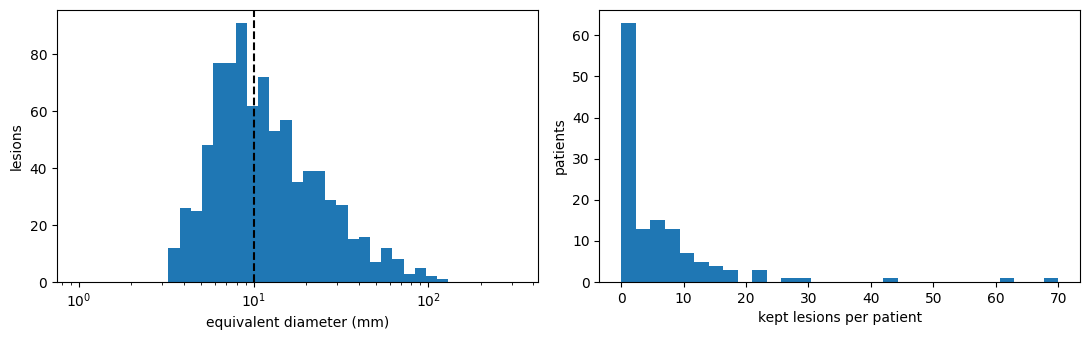

In [8]:
fold_of = {c: int(k) for k, v in FOLDS.items() for c in v}
census = pd.DataFrame([{"case": c, "fold": fold_of[c], **l} for c in case_ids for l in INFO[c]["lesions"]])
per_case = census.groupby("case").size().reindex(case_ids, fill_value=0)

print(f"cases: {len(case_ids)} | without any kept lesion: {(per_case == 0).sum()}")
print(f"kept lesions: {len(census)} | ignored tiny components: {sum(INFO[c]['n_ignored_components'] for c in case_ids)}")
print(f"lesions per case: median {per_case.median():.0f}, max {per_case.max()}")
census["small"] = census["diam_mm"] < SMALL_DIAM_MM
print(f"\nsmall lesions (< {SMALL_DIAM_MM} mm): {census['small'].sum()} in {census.loc[census['small'], 'case'].nunique()} patients")
print("small lesions per fold:\n", census.groupby("fold")["small"].sum().to_string())
top = census[census["small"]].groupby("case").size().sort_values(ascending=False)
if len(top):
    print(f"\nshare of small lesions held by the 5 patients with most: {top.head(5).sum() / top.sum():.0%}")
print("\ncount by diameter bin (mm):")
print(pd.cut(census["diam_mm"], [0, 5, 10, 20, 50, np.inf]).value_counts().sort_index().to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(census["diam_mm"], bins=np.logspace(0, 2.5, 40)); ax[0].set_xscale("log")
ax[0].axvline(SMALL_DIAM_MM, color="k", ls="--"); ax[0].set_xlabel("equivalent diameter (mm)"); ax[0].set_ylabel("lesions")
ax[1].hist(per_case, bins=30); ax[1].set_xlabel("kept lesions per patient"); ax[1].set_ylabel("patients")
plt.tight_layout(); plt.show()

In [9]:
from monai.transforms import (Compose, RandFlipd, RandAffined, RandGaussianNoised,
                              RandScaleIntensityd, RandShiftIntensityd)

def make_augment():
    keys = ["image", "label"]
    return Compose([
        RandFlipd(keys=keys, prob=0.5, spatial_axis=0),
        RandFlipd(keys=keys, prob=0.5, spatial_axis=1),
        RandFlipd(keys=keys, prob=0.5, spatial_axis=2),
        RandAffined(keys=keys, prob=0.3, rotate_range=(0.26, 0.26, 0.26), scale_range=(0.15, 0.15, 0.15),
                    mode=("bilinear", "nearest"), padding_mode="zeros"),
        RandGaussianNoised(keys="image", prob=0.15, std=0.03),
        RandScaleIntensityd(keys="image", factors=0.15, prob=0.2),
        RandShiftIntensityd(keys="image", offsets=0.05, prob=0.2),
    ])

def _plain(x):
    return x.as_tensor() if hasattr(x, "as_tensor") else torch.as_tensor(x)

KIND_RANDOM, KIND_FG, KIND_TUMOR = 0, 1, 2

class PatchDataset(torch.utils.data.Dataset):
    """Each item is one random crop from a random training case."""

    def __init__(self, case_ids, sampler, length, augment=True):
        assert sampler in ("standard", "tumor_voxel", "lesion")
        self.case_ids, self.sampler, self.length = list(case_ids), sampler, int(length)
        self.aug = make_augment() if augment else None
        self._cache, self._r = {}, None

    def __len__(self):
        return self.length

    def _rng(self):
        if self._r is None:   # created inside each worker, seeded from that worker's torch seed
            self._r = np.random.default_rng(int(torch.randint(0, 2**31 - 1, (1,)).item()))
        return self._r

    def _case(self, cid):
        if cid not in self._cache:
            z = np.load(PREP_DIR / cid / "coords.npz")
            self._cache[cid] = {
                "image": np.load(PREP_DIR / cid / "image.npy", mmap_mode="r"),
                "label": np.load(PREP_DIR / cid / "label.npy", mmap_mode="r"),
                "tumor": z["tumor"], "offsets": z["offsets"], "fg": z["fg"], "diams": z["diams"]}
        return self._cache[cid]

    def _center(self, c, rng):
        shape = c["image"].shape
        n_les = len(c["diams"])
        u = rng.random()
        want_tumor = self.sampler != "standard" and u >= 1.0 - TUMOR_CROP_FRAC
        if u < RANDOM_CROP_FRAC or len(c["fg"]) == 0:
            return np.array([rng.integers(s) for s in shape]), KIND_RANDOM, -1.0
        if want_tumor and n_les > 0:
            if self.sampler == "tumor_voxel":
                row = int(rng.integers(len(c["tumor"])))
                li = int(np.searchsorted(c["offsets"], row, side="right") - 1)
            else:
                li = int(rng.integers(n_les))
                row = int(rng.integers(c["offsets"][li], c["offsets"][li + 1]))
            return c["tumor"][row].astype(np.int64), KIND_TUMOR, float(c["diams"][li])
        return c["fg"][rng.integers(len(c["fg"]))].astype(np.int64), KIND_FG, -1.0

    def __getitem__(self, idx):
        rng = self._rng()
        c = self._case(self.case_ids[int(rng.integers(len(self.case_ids)))])
        center, kind, diam = self._center(c, rng)
        shape = c["image"].shape
        sl = []
        for a in range(3):
            p = PATCH[a]
            jitter = int(rng.integers(-(p // 4), p // 4 + 1))      # target is not always dead centre
            start = int(np.clip(center[a] + jitter - p // 2, 0, max(shape[a] - p, 0)))
            sl.append(slice(start, min(start + p, shape[a])))
        img = np.array(c["image"][tuple(sl)], dtype=np.float32)
        lab = np.array(c["label"][tuple(sl)], dtype=np.uint8)
        if img.shape != tuple(PATCH):
            pad = [(0, PATCH[a] - img.shape[a]) for a in range(3)]
            img, lab = np.pad(img, pad), np.pad(lab, pad)
        d = {"image": img[None], "label": lab[None]}
        if self.aug is not None:
            d = self.aug(d)
        return {"image": _plain(d["image"]).float().contiguous(),
                "label": _plain(d["label"]).long().contiguous(),
                "kind": kind, "diam": diam}

In [10]:
class ConvBlock(nn.Sequential):
    def __init__(self, cin, cout, stride=1):
        super().__init__(
            nn.Conv3d(cin, cout, 3, stride, 1, bias=False), nn.InstanceNorm3d(cout, affine=True), nn.LeakyReLU(0.01, inplace=True),
            nn.Conv3d(cout, cout, 3, 1, 1, bias=False), nn.InstanceNorm3d(cout, affine=True), nn.LeakyReLU(0.01, inplace=True))

class AttentionGate(nn.Module):
    def __init__(self, c_x, c_g, c_int):
        super().__init__()
        self.wx = nn.Conv3d(c_x, c_int, 1, bias=False)
        self.wg = nn.Conv3d(c_g, c_int, 1)
        self.psi = nn.Conv3d(c_int, 1, 1)
        nn.init.constant_(self.psi.bias, 3.0)      # sigmoid(3) ~ 0.95: gate starts open
        self.keep_map, self.last_map = False, None

    def forward(self, x, g):
        alpha = torch.sigmoid(self.psi(F.relu(self.wx(x) + self.wg(g))))
        if self.keep_map:
            self.last_map = alpha.detach().float().cpu()
        return x * alpha

class UNet3D(nn.Module):
    def __init__(self, in_ch=1, n_classes=3, channels=CHANNELS, attention=False, attn_levels=ATTN_LEVELS):
        super().__init__()
        ch = list(channels)
        self.enc = nn.ModuleList([ConvBlock(in_ch, ch[0])] + [ConvBlock(ch[i - 1], ch[i], 2) for i in range(1, len(ch))])
        self.up, self.dec, self.gates = nn.ModuleList(), nn.ModuleList(), nn.ModuleDict()
        self.levels = list(reversed(range(len(ch) - 1)))
        for i in self.levels:
            self.up.append(nn.ConvTranspose3d(ch[i + 1], ch[i], 2, 2))
            self.dec.append(ConvBlock(2 * ch[i], ch[i]))
            if attention and i in attn_levels:
                self.gates[str(i)] = AttentionGate(ch[i], ch[i], max(ch[i] // 2, 8))
        self.head = nn.Conv3d(ch[0], n_classes, 1)

    def forward(self, x):
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x)
            if i < len(self.enc) - 1:
                skips.append(x)
        for k, i in enumerate(self.levels):
            x = self.up[k](x)
            s = skips[i]
            if str(i) in self.gates:
                s = self.gates[str(i)](s, x)
            x = self.dec[k](torch.cat([s, x], dim=1))
        return self.head(x)

def build_model(arch):
    assert arch in ("unet", "attn")
    return UNet3D(attention=(arch == "attn"))

for a in ("unet", "attn"):
    print(a, f"{sum(p.numel() for p in build_model(a).parameters()) / 1e6:.3f} M parameters")

unet 16.544 M parameters
attn 16.549 M parameters


In [11]:
rows = []
for s in ("standard", "tumor_voxel", "lesion"):
    ds = PatchDataset(FOLDS["1"] + FOLDS["2"], s, 400, augment=False)
    kinds, diams, tumor_frac = [], [], []
    for i in range(len(ds)):
        b = ds[i]
        kinds.append(b["kind"]); diams.append(b["diam"]); tumor_frac.append(float((b["label"] == 2).any()))
    kinds, diams = np.array(kinds), np.array(diams)
    t = kinds == KIND_TUMOR
    rows.append({"sampler": s, "random": (kinds == KIND_RANDOM).mean(), "foreground": (kinds == KIND_FG).mean(),
                 "tumour-centred": t.mean(), "crops containing tumour": np.mean(tumor_frac),
                 "median target diam (mm)": np.median(diams[t]) if t.any() else np.nan,
                 "small targets / tumour crops": (diams[t] < SMALL_DIAM_MM).mean() if t.any() else np.nan})
display(pd.DataFrame(rows).set_index("sampler").round(3))

,random,foreground,tumour-centred,crops containing tumour,median target diam (mm),small targets / tumour crops
sampler,,,,,,
standard,0.305,0.695,0.000,0.512,NaN,NaN
tumor_voxel,0.355,0.358,0.288,0.550,24.240,0.087
lesion,0.325,0.385,0.290,0.572,13.001,0.388


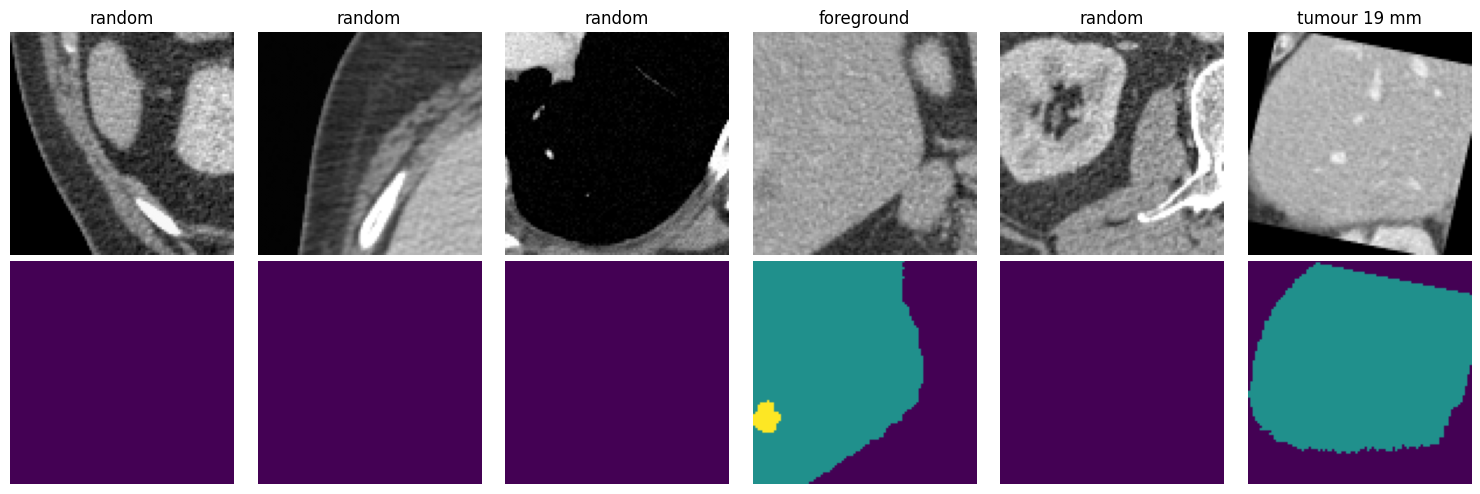

In [12]:
ds = PatchDataset(FOLDS["1"], "lesion", 6, augment=True)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j in range(6):
    b = ds[j]
    z = PATCH[2] // 2
    axes[0, j].imshow(b["image"][0, :, :, z].T, cmap="gray", origin="lower", vmin=0, vmax=1)
    axes[1, j].imshow(b["label"][0, :, :, z].T, origin="lower", vmin=0, vmax=2)
    axes[0, j].set_title(["random", "foreground", f"tumour {b['diam']:.0f} mm"][b["kind"]]); axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

In [13]:
if DEVICE.type == "cuda":
    m = build_model("attn").to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    x = torch.rand(BATCH_SIZE, 1, *PATCH, device=DEVICE); y = torch.randint(0, 3, (BATCH_SIZE, 1, *PATCH), device=DEVICE)
    lf = DiceCELoss(to_onehot_y=True, softmax=True)
    torch.cuda.reset_peak_memory_stats(); t0 = time.time()
    for _ in range(5):
        with torch.autocast("cuda", enabled=AMP):
            out = m(x)
        loss = lf(out.float(), y); opt.zero_grad(); loss.backward(); opt.step()
    torch.cuda.synchronize()
    its = 5 / (time.time() - t0)
    print(f"peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.1f} GB | ~{its:.1f} it/s (GPU only) "
          f"| {TOTAL_ITERS} iterations ~ {TOTAL_ITERS / its / 3600:.1f} h per run before data-loading overhead")
    del m, opt, x, y, out, loss; torch.cuda.empty_cache()

peak GPU memory 4.3 GB | ~2.2 it/s (GPU only) | 25000 iterations ~ 3.1 h per run before data-loading overhead


In [14]:
def run_dir(arch, sampler, fold):
    return RUNS_DIR / EXP / f"{arch}__{sampler}__fold{fold}"

def _atomic_save(obj, path):
    tmp = Path(str(path) + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

def _grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=AMP and DEVICE.type == "cuda")
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=AMP and DEVICE.type == "cuda")

def train_run(arch, sampler, fold, deadline=None):
    """Returns True when the run is complete, False if it stopped early at the deadline."""
    rd = run_dir(arch, sampler, fold)
    rd.mkdir(parents=True, exist_ok=True)
    if (rd / "final.pt").exists():
        return True

    torch.manual_seed(SEED + 1000 * fold)      # same initial weights for every sampler within (architecture, fold)
    model = build_model(arch).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda it: max(0.0, 1.0 - it / TOTAL_ITERS) ** 0.9)
    scaler = _grad_scaler()
    loss_fn = DiceCELoss(to_onehot_y=True, softmax=True)
    it0 = 0
    if (rd / "last.pt").exists():
        ck = torch.load(rd / "last.pt", map_location=DEVICE, weights_only=False)
        assert ck["total_iters"] == TOTAL_ITERS, "checkpoint was made with a different TOTAL_ITERS"
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        it0 = ck["iter"]
    torch.manual_seed(SEED + 1000 * fold + it0)

    train_ids = [c for k, v in FOLDS.items() if int(k) != fold for c in v]
    ds = PatchDataset(train_ids, sampler, (TOTAL_ITERS - it0) * BATCH_SIZE)
    dl = monai.data.DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                               pin_memory=True, drop_last=True)
    log_path = rd / "train_log.csv"
    if it0 == 0:
        log_path.write_text("iter,loss,lr,frac_tumor_crops,frac_small_target,it_per_s\n")

    def checkpoint(it):
        _atomic_save({"iter": it, "total_iters": TOTAL_ITERS, "model": model.state_dict(), "opt": opt.state_dict(),
                      "sched": sched.state_dict(), "scaler": scaler.state_dict()}, rd / "last.pt")

    model.train()
    acc_loss, n_crops, n_tumor, n_small, t_log = 0.0, 0, 0, 0, time.time()
    pbar = tqdm(dl, initial=it0, total=TOTAL_ITERS, desc=f"{arch}/{sampler}/fold{fold}", leave=False)
    it = it0
    for it, batch in enumerate(pbar, start=it0 + 1):
        x = batch["image"].to(DEVICE, non_blocking=True)
        y = batch["label"].to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE.type, enabled=AMP and DEVICE.type == "cuda"):
            logits = model(x)
        loss = loss_fn(logits.float(), y)
        if not torch.isfinite(loss):
            raise RuntimeError(f"non-finite loss at iteration {it} in {rd.name}")
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 12.0)
        scaler.step(opt); scaler.update(); sched.step()

        acc_loss += loss.item(); n_crops += len(batch["kind"])
        is_t = batch["kind"] == KIND_TUMOR
        n_tumor += int(is_t.sum()); n_small += int((is_t & (batch["diam"] < SMALL_DIAM_MM)).sum())
        if it % LOG_EVERY == 0:
            ips = LOG_EVERY / (time.time() - t_log)
            with open(log_path, "a") as f:
                f.write(f"{it},{acc_loss / LOG_EVERY:.5f},{sched.get_last_lr()[0]:.3e},"
                        f"{n_tumor / n_crops:.4f},{n_small / n_crops:.4f},{ips:.2f}\n")
            pbar.set_postfix(loss=f"{acc_loss / LOG_EVERY:.3f}", it_s=f"{ips:.1f}")
            acc_loss, n_crops, n_tumor, n_small, t_log = 0.0, 0, 0, 0, time.time()
        if it % CKPT_EVERY == 0 and it < TOTAL_ITERS:
            checkpoint(it)
            if deadline is not None and time.time() > deadline:
                print(f"time budget reached: {rd.name} paused at iteration {it}")
                return False

    assert it == TOTAL_ITERS, f"stopped at {it}, expected {TOTAL_ITERS}"
    _atomic_save({"model": model.state_dict(), "arch": arch, "sampler": sampler, "fold": fold,
                  "total_iters": TOTAL_ITERS}, rd / "final.pt")
    (rd / "last.pt").unlink(missing_ok=True)
    return True

In [15]:
def _largest_component(mask):
    cc, n = ndi.label(mask, structure=S26)
    if n <= 1:
        return mask
    sizes = np.bincount(cc.ravel())
    sizes[0] = 0
    return cc == sizes.argmax()

def liver_roi(p_bg):
    """Largest connected component of the predicted liver(+tumour), and the same mask dilated by LIVER_MARGIN_VOX."""
    liver = _largest_component(p_bg < 0.5)
    return liver, ndi.binary_dilation(liver, iterations=LIVER_MARGIN_VOX)

def score_case(cid, p_bg, p_tumor, liver_mask=False):
    """Whole-volume metrics for one case. Pure numpy; all thresholds come from the config cell.
    liver_mask=True is the secondary analysis: liver = largest predicted component, tumour predictions outside it are removed."""
    lab = np.load(PREP_DIR / cid / "label.npy")
    lm = np.load(PREP_DIR / cid / "lesions.npy").astype(np.int64)
    diams = np.array([l["diam_mm"] for l in INFO[cid]["lesions"]], dtype=float)
    K = len(diams)
    small = diams < SMALL_DIAM_MM

    liver_gt, liver_pred = lab > 0, p_bg < 0.5
    if liver_mask:
        liver_pred, roi = liver_roi(p_bg)
        p_tumor = np.where(roi, p_tumor, 0.0)
    denom = liver_gt.sum() + liver_pred.sum()
    case = {"case": cid, "liver_dice": 2.0 * (liver_gt & liver_pred).sum() / denom if denom else np.nan,
            "n_lesions": K, "n_small": int(small.sum())}

    # everything tumour-related happens inside the bounding box of (any candidate prediction | any GT tumour)
    region = (p_tumor > min(FROC_THRESHOLDS)) | (lab == 2)
    if region.any():
        box = tuple(slice(int(np.argmax(v)), int(len(v) - np.argmax(v[::-1])))
                    for v in (region.any(axis=(1, 2)), region.any(axis=(0, 2)), region.any(axis=(0, 1))))
    else:
        box = (slice(0, 1),) * 3
    p_tumor, lab, lm = p_tumor[box], lab[box], lm[box]
    tumor_gt = lab == 2          # ALL annotated tumour voxels, including ignored tiny components:
                                 # used for tumour Dice, and a prediction touching any of them is never a false positive
    liver_gt = lab > 0
    kept = lm > 0                # voxels of evaluable lesions (>= MIN_LESION_MM3): used for lesion-wise sensitivity
    tot = np.bincount(lm[kept], minlength=K + 1)[1:]

    lesion_rows, froc_rows = [], []
    for t in FROC_THRESHOLDS:
        pcc, n = ndi.label(p_tumor > t, structure=S26)
        psize = np.bincount(pcc.ravel(), minlength=n + 1)
        keep = psize * VOX_MM3 >= MIN_LESION_MM3      # predicted components below the minimum size are dropped
        keep[0] = False
        pred = keep[pcc]
        hit = np.zeros(n + 1, dtype=bool)
        hit[np.unique(pcc[tumor_gt])] = True
        fp = keep & ~hit                              # predicted components touching no ground-truth tumour voxel
        n_fp = int(fp.sum())
        cover = np.bincount(lm[kept & pred], minlength=K + 1)[1:] / np.maximum(tot, 1)
        det = cover >= MATCH_MIN_COVER
        froc_rows.append({"case": cid, "threshold": t, "n_fp": n_fp, "n_all": K, "n_all_det": int(det.sum()),
                          "n_small": int(small.sum()), "n_small_det": int((det & small).sum())})
        if abs(t - 0.5) < 1e-9:
            in_liver = np.zeros(n + 1, dtype=bool)
            in_liver[np.unique(pcc[liver_gt])] = True  # diagnostic only: does the FP touch the ground-truth liver?
            d2 = tumor_gt.sum() + pred.sum()
            case.update({"tumor_dice": 2.0 * (tumor_gt & pred).sum() / d2 if tumor_gt.any() else np.nan,  # only defined when GT tumour exists
                         "n_fp": n_fp, "n_fp_in_liver": int((fp & in_liver).sum()), "n_fp_outside_liver": int((fp & ~in_liver).sum()),
                         "n_det": int(det.sum()), "n_small_det": int((det & small).sum())})
            lesion_rows = [{"case": cid, "lesion": i + 1, "diam_mm": diams[i], "small": bool(small[i]),
                            "cover": float(cover[i]), "detected": bool(det[i])} for i in range(K)]
    return case, lesion_rows, froc_rows

@torch.no_grad()
def predict_probs(model, x):
    """Sliding-window class probabilities, averaged over the mirrored copies listed in TTA_AXES."""
    acc = None
    for axes in TTA_AXES:
        xi = torch.flip(x, dims=[a + 2 for a in axes]) if axes else x
        with torch.autocast(DEVICE.type, enabled=AMP and DEVICE.type == "cuda"):
            logits = sliding_window_inference(xi, PATCH, SW_BATCH, model, overlap=0.5, mode="gaussian",
                                              sw_device=DEVICE, device="cpu")
        p = torch.softmax(logits[0].float(), dim=0)
        if axes:
            p = torch.flip(p, dims=[a + 1 for a in axes])
        acc = p if acc is None else acc + p
        del logits
    return (acc / len(TTA_AXES)).numpy()

EVAL_VARIANTS = {"": False, "_livermask": True}     # file suffix -> liver_mask flag
EVAL_MARKER = "froc_livermask.csv"                  # written last: marks a run as evaluated with the current code

@torch.no_grad()
def evaluate_run(arch, sampler, fold, force=False):
    rd = run_dir(arch, sampler, fold)
    if (rd / EVAL_MARKER).exists() and not force:
        return
    model = build_model(arch).to(DEVICE)
    model.load_state_dict(torch.load(rd / "final.pt", map_location=DEVICE, weights_only=False)["model"])
    model.eval()
    res = {suf: ([], [], []) for suf in EVAL_VARIANTS}
    for cid in tqdm(FOLDS[str(fold)], desc=f"eval {rd.name}", leave=False):
        x = torch.from_numpy(np.load(PREP_DIR / cid / "image.npy").astype(np.float32))[None, None]
        prob = predict_probs(model, x)
        for suf, flag in EVAL_VARIANTS.items():
            c, l, f = score_case(cid, prob[0], prob[2], liver_mask=flag)
            res[suf][0].append(c); res[suf][1].extend(l); res[suf][2].extend(f)
        del prob
    tag = {"arch": arch, "sampler": sampler, "fold": fold, "n_tta": len(TTA_AXES)}
    for suf, (cases, lesions, froc) in res.items():
        pd.DataFrame(cases).assign(**tag).to_csv(rd / f"cases{suf}.csv", index=False)
        pd.DataFrame(lesions, columns=["case", "lesion", "diam_mm", "small", "cover", "detected"]).assign(**tag).to_csv(rd / f"lesions{suf}.csv", index=False)
        pd.DataFrame(froc).assign(**tag).to_csv(rd / f"froc{suf}.csv", index=False)

def status():
    rows = []
    for fold in FOLDS_TO_RUN:
        for arch, sampler in CONFIGS:
            rd = run_dir(arch, sampler, fold)
            it = TOTAL_ITERS if (rd / "final.pt").exists() else 0
            if not it and (rd / "train_log.csv").exists():
                log = pd.read_csv(rd / "train_log.csv")
                it = int(log["iter"].iloc[-1]) if len(log) else 0
            rows.append({"fold": fold, "config": f"{arch}/{sampler}", "iter": it,
                         "trained": (rd / "final.pt").exists(), "evaluated": (rd / EVAL_MARKER).exists()})
    return pd.DataFrame(rows)

In [ ]:
deadline = time.time() + MAX_HOURS_PER_CALL * 3600 if MAX_HOURS_PER_CALL else None
stopped = False
for fold in FOLDS_TO_RUN:
    for arch, sampler in CONFIGS:
        if not train_run(arch, sampler, fold, deadline):
            stopped = True
            break
        evaluate_run(arch, sampler, fold)
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    if stopped:
        break
display(status())

<local-environment> UserWarning: This DataLoader will create 6 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


attn/lesion/fold1:   6%|6         | 1500/25000 [00:00<?, ?it/s]

eval attn__lesion__fold1:   0%|          | 0/26 [00:00<?, ?it/s]

<local-environment> UserWarning: This DataLoader will create 6 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


unet/tumor_voxel/fold1:   0%|          | 0/25000 [00:00<?, ?it/s]

eval unet__tumor_voxel__fold1:   0%|          | 0/26 [00:00<?, ?it/s]

<local-environment> UserWarning: This DataLoader will create 6 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


unet/standard/fold2:   0%|          | 0/25000 [00:00<?, ?it/s]

In [ ]:
# Training curves and realised crop mix for the runs of one fold
fold = FOLDS_TO_RUN[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for arch, sampler in CONFIGS:
    p = run_dir(arch, sampler, fold) / "train_log.csv"
    if p.exists() and len(log := pd.read_csv(p)):
        ax[0].plot(log["iter"], log["loss"].rolling(10, min_periods=1).mean(), label=f"{arch}/{sampler}")
        ax[1].plot(log["iter"], log["frac_small_target"].rolling(10, min_periods=1).mean(), label=f"{arch}/{sampler}")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("training loss"); ax[0].legend()
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("fraction of crops centred on a small lesion")
plt.tight_layout(); plt.show()

In [ ]:
# "" = raw predictions (primary analysis); "_livermask" = tumour predictions restricted to the predicted liver (secondary)
VARIANT = ""

def load_results(name):
    frames = []
    for fold in FOLDS_TO_RUN:
        for arch, sampler in CONFIGS:
            p = run_dir(arch, sampler, fold) / f"{name}{VARIANT}.csv"
            if (run_dir(arch, sampler, fold) / EVAL_MARKER).exists():
                frames.append(pd.read_csv(p))
    if not frames:
        return pd.DataFrame()
    df = pd.concat(frames, ignore_index=True)
    df["config"] = df["arch"] + "/" + df["sampler"]
    return df

cases_df, lesions_df, froc_df = load_results("cases"), load_results("lesions"), load_results("froc")
assert len(cases_df), "no evaluated runs yet"

g = cases_df.groupby("config")
summary = pd.DataFrame({
    "patients": g.size(),
    "small-lesion sensitivity": g["n_small_det"].sum() / g["n_small"].sum(),
    "all-lesion sensitivity": g["n_det"].sum() / g["n_lesions"].sum(),
    "FP per scan": g["n_fp"].mean(),
    "of which outside GT liver": g["n_fp_outside_liver"].mean(),
    "tumour Dice (cases with tumour)": g["tumor_dice"].mean(),
    "liver Dice": g["liver_dice"].mean()})
display(summary.round(3))

if len(lesions_df):
    lesions_df["size bin (mm)"] = pd.cut(lesions_df["diam_mm"], [0, 10, 20, np.inf])
    print("lesion-wise sensitivity by size (n lesions in brackets is the same for every configuration)")
    display(lesions_df.groupby(["config", "size bin (mm)"], observed=True)["detected"].mean().unstack().round(3))
    display(lesions_df.groupby("size bin (mm)", observed=True)["lesion"].size().div(lesions_df["config"].nunique()).rename("n lesions").to_frame().T)

In [ ]:
def _metric(tab, idx, metric):
    """tab: dict of per-patient arrays; idx: (n_boot, n_patients) resampling indices."""
    if metric == "small_sens":
        return tab["n_small_det"][idx].sum(1) / np.maximum(tab["n_small"][idx].sum(1), 1)
    if metric == "fp_per_scan":
        return tab["n_fp"][idx].mean(1)
    if metric == "tumor_dice":
        return np.nanmean(tab["tumor_dice"][idx], axis=1)
    raise ValueError(metric)

def paired_bootstrap(weights, metric, n_boot=5000, seed=0):
    """weights: {config: weight}. Returns the point estimate and 95% CI of sum_k w_k * metric(config k)."""
    if any(c not in set(cases_df["config"]) for c in weights):
        return None
    wide = {c: cases_df[cases_df["config"] == c].set_index("case") for c in weights}
    common = sorted(set.intersection(*(set(w.index) for w in wide.values())))
    tabs = {c: {k: w.loc[common, k].to_numpy(dtype=float) for k in ("n_small", "n_small_det", "n_fp", "tumor_dice")}
            for c, w in wide.items()}
    n = len(common)
    idx = np.random.default_rng(seed).integers(0, n, size=(n_boot, n))
    point = sum(w * _metric(tabs[c], np.arange(n)[None], metric)[0] for c, w in weights.items())
    boot = sum(w * _metric(tabs[c], idx, metric) for c, w in weights.items())
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    return {"estimate": point, "ci_low": lo, "ci_high": hi, "patients": n}

CONTRASTS = {
    "PRIMARY  lesion - tumour-voxel (U-Net, equal tumour-crop rate)": {"unet/lesion": 1, "unet/tumor_voxel": -1},
    "tumour-voxel - standard (U-Net): effect of tumour oversampling": {"unet/tumor_voxel": 1, "unet/standard": -1},
    "lesion - standard (U-Net): both effects combined":               {"unet/lesion": 1, "unet/standard": -1},
    "lesion - standard (attention): both effects combined":           {"attn/lesion": 1, "attn/standard": -1},
    "attention - U-Net (standard sampling)":          {"attn/standard": 1, "unet/standard": -1},
    "attention - U-Net (lesion sampling)":            {"attn/lesion": 1, "unet/lesion": -1},
    "interaction: sampling x attention (exploratory)": {"attn/lesion": 1, "attn/standard": -1, "unet/lesion": -1, "unet/standard": 1},
}
rows = []
for name, w in CONTRASTS.items():
    for metric in ("small_sens", "fp_per_scan", "tumor_dice"):
        r = paired_bootstrap(w, metric)
        if r:
            rows.append({"contrast": name, "metric": metric, **r})
if rows:
    display(pd.DataFrame(rows).set_index(["contrast", "metric"]).round(3))
else:
    print("not enough evaluated configurations for any contrast yet")

In [ ]:
# FROC: small-lesion sensitivity against false positives per scan, and sensitivity at a matched false-positive rate
fg = froc_df.groupby(["config", "threshold"])
froc = pd.DataFrame({"fp_per_scan": fg["n_fp"].mean(),
                     "small_sens": fg["n_small_det"].sum() / fg["n_small"].sum(),
                     "all_sens": fg["n_all_det"].sum() / fg["n_all"].sum()}).reset_index()
fig, ax = plt.subplots(figsize=(6, 4))
for cfg, d in froc.groupby("config"):
    d = d.sort_values("fp_per_scan")
    ax.plot(d["fp_per_scan"], d["small_sens"], marker="o", label=cfg)
ax.set_xlabel("false positives per scan"); ax.set_ylabel(f"sensitivity, lesions < {SMALL_DIAM_MM:g} mm"); ax.legend()
plt.tight_layout(); plt.show()

REF = "unet/standard"
if REF in set(froc["config"]):
    ref_fp = float(froc[(froc["config"] == REF) & (froc["threshold"] == 0.5)]["fp_per_scan"].iloc[0])
    matched = {}
    for cfg, d in froc.groupby("config"):
        d = d.sort_values("fp_per_scan")
        inside = d["fp_per_scan"].min() <= ref_fp <= d["fp_per_scan"].max()
        matched[cfg] = float(np.interp(ref_fp, d["fp_per_scan"], d["small_sens"])) if inside else np.nan
    print(f"small-lesion sensitivity at {ref_fp:.2f} FP/scan (the rate of {REF} at threshold 0.5; NaN = outside the measured range)")
    # fixed operating points, reported where the curve reaches them
    fixed = {cfg: {f"{r:g} FP/scan": (float(np.interp(r, d.sort_values('fp_per_scan')['fp_per_scan'], d.sort_values('fp_per_scan')['small_sens'])) if d['fp_per_scan'].min() <= r <= d['fp_per_scan'].max() else np.nan) for r in (1, 2, 4, 8)} for cfg, d in froc.groupby('config')}
    display(pd.DataFrame(fixed).T.round(3))
    display(pd.Series(matched, name="small_sens @ matched FP").round(3).to_frame())

In [ ]:
out = RUNS_DIR / EXP / f"results{VARIANT}"
out.mkdir(exist_ok=True)
summary.to_csv(out / "summary.csv"); froc.to_csv(out / "froc.csv", index=False)
if rows:
    pd.DataFrame(rows).to_csv(out / "contrasts.csv", index=False)
cases_df.to_csv(out / "all_cases.csv", index=False); lesions_df.to_csv(out / "all_lesions.csv", index=False)
print("saved to", out)